# Cross-task decoding

**Draft for NeurodeskEDU — synthetic demonstration, not research results.**

Train a linear classifier to distinguish human from computer context in Shared Reward, then evaluate its transfer to Trust in unseen participants. We start from precomputed signed outcome COPEs, so no fMRI preprocessing or first-level GLM estimation runs in this notebook.

**Authors:** David V. Smith; Jacob and Riccardo (full names, contributions and final author list to confirm).  
**Draft date:** October 27, 2026.  
**Proposed licenses:** MIT for code; CC BY 4.0 for original explanations. Source data and software retain their own licenses.  
**Intended audience:** students with basic Python and introductory fMRI/GLM knowledge.

<details><summary>AI assistance and review status</summary>
OpenAI Codex assisted with the initial code and explanations. Human scientific review, actual-public-data execution and fresh Neurodesk Play testing remain pending. This is not a submission-ready notebook.
</details>

## What you will learn

1. Distinguish a signed effect estimate (COPE) from a z-statistic and a decoder coefficient.
2. Keep each participant's conditions and tasks in a single cross-validation fold.
3. Compare within-task prediction and cross-task transfer on the same held-out people.
4. Plot decoder coefficients and a Haufe-style forward pattern without treating either as a causal brain map.

**The data boundary:** the intended real-data source is the public N=114 release, OpenNeuro **ds005123 v1.0.0**. The actual tutorial N will be smaller after protected validation membership, QC and completeness checks. A curator must exclude the union of the sealed N=50 and all reserved external validation participants **before** exporting any images. The tutorial never loads those membership lists, main-project caches, frozen paper models or validation images.

## Citations and resources

- Original dataset: [OpenNeuro ds005123 v1.0.0](https://doi.org/10.18112/openneuro.ds005123.v1.0.0), whose metadata specifies CC0. Cite the corresponding [data paper](https://pubmed.ncbi.nlm.nih.gov/39252767/) as well.
- Derived educational maps: **version-specific Zenodo DOI pending**. The release must document source contrast names/weights, outcome phase, retained run strategy, preprocessing, QC, grid, independent mask source and file checksums.
- [Neurodesk citation guidance](https://neurodesk.org/overview/how-to-cite-us/) and [NeurodeskEDU template](https://github.com/neurodesk/neurodeskedu/blob/main/books/examples/template.ipynb).
- Scikit-learn: [Pedregosa et al., 2011](https://jmlr.org/papers/v12/pedregosa11a.html); [NIfTI handling with NiBabel](https://nipy.org/nibabel/).
- Forward-pattern interpretation: [Haufe et al., 2014](https://doi.org/10.1016/j.neuroimage.2013.10.067).

This synthetic draft is useful for checking code flow. Its accuracies, maps, confidence intervals and timing do not characterize human data.

## 1. Environment and fixed choices

Use the proposed `requirements.txt` while testing this draft; confirm a compatible environment in Neurodesk Play before submission. This example uses Python packages only, so it needs no FSL module. It uses Matplotlib directly for static figures.

The fixed choices below explain a simple classifier. Do not change them repeatedly to improve accuracy. The tutorial analysis is independent of candidate selection for the paper.

In [1]:
from pathlib import Path
import hashlib, importlib.metadata, importlib.util, itertools, json, os, platform
import shutil, stat, tempfile, time, urllib.parse, urllib.request, zipfile
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.svm import LinearSVC
from IPython.display import display

MODE = "synthetic"  # Final release: "public" only after the approved archive exists.
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs" / MODE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED, N_FOLDS, C = 20261027, 5, 1.0
TASKS = ("sharedreward", "trust")
PARTNERS = ("computer", "friend", "stranger")
VALENCES = ("positive", "negative")
STARTED = time.perf_counter()
LABEL = "SYNTHETIC FIXTURE — not human results" if MODE == "synthetic" else "Public educational subset"
assert MODE in ("synthetic", "public")
print(LABEL)

SYNTHETIC FIXTURE — not human results


## 2. Retrieve a fixed data release

For real data, the notebook downloads **one frozen, checksum-verified archive**. It does not discover data from a mutable directory or scan a local research checkout. The archive contains 12 COPEs per person: two tasks × three partners × two valences. An independent fixed mask and a small metadata manifest accompany the maps.

**This draft defaults to a labelled synthetic fixture.** There is no automatic fallback to synthetic data if a real download fails. Public mode stops until a curated release URL, DOI, checksums and membership-audit attestations are supplied in `data_release.json`.

In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def public_release(config):
    assert config["status"] == "published", "Publish and review the educational release first."
    assert config["source_dataset"] == "ds005123" and config["source_version"] == "1.0.0"
    assert config["derivative_doi"] and config["expected_n"] > N_FOLDS
    audit_keys = {"public_release_only", "sealed_N50_excluded", "external_validation_excluded", "qc_and_complete_maps_verified"}
    assert all(config["membership_audit"].get(key) is True for key in audit_keys), "Curator membership/QC audit is incomplete."
    assert config["mask_provenance"]["kind"] == "independent_template"
    assert config["mask_provenance"]["description"] and config["mask_provenance"]["source_url"]
    url, expected = config["archive_url"], config["archive_sha256"]
    assert urllib.parse.urlsplit(url).scheme == "https"
    assert urllib.parse.urlsplit(url).hostname == "zenodo.org", "Use the reviewed Zenodo record URL."
    assert len(expected) == 64 and all(c in "0123456789abcdef" for c in expected)
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive = DATA_DIR / (expected + ".zip")
    if not archive.exists():
        temporary = archive.with_suffix(".part")
        try:
            with urllib.request.urlopen(url, timeout=90) as source, temporary.open("wb") as target:
                total = 0
                for block in iter(lambda: source.read(1024 * 1024), b""):
                    total += len(block)
                    assert total <= config["max_download_bytes"], "Download exceeds reviewed limit."
                    target.write(block)
            assert sha256(temporary) == expected, "Archive checksum mismatch."
            temporary.replace(archive)
        finally:
            temporary.unlink(missing_ok=True)
    assert sha256(archive) == expected, "Cached archive changed."
    destination = DATA_DIR / ("public-" + expected[:16])
    assert not destination.is_symlink()
    if destination.exists():
        assert all(not p.is_symlink() for p in destination.rglob("*")), "Symlink in cached extraction."
    with zipfile.ZipFile(archive) as z:
        assert sum(i.file_size for i in z.infolist()) <= config["max_uncompressed_bytes"]
        for info in z.infolist():
            parts = Path(info.filename).parts
            assert not Path(info.filename).is_absolute() and ".." not in parts
            assert not stat.S_ISLNK(info.external_attr >> 16), "Archive symlinks are not allowed."
        z.extractall(destination)
    print("Derivative DOI:", config["derivative_doi"])
    return destination, config["expected_n"]

### Synthetic fixture for draft testing

The fixture creates an independently specified spherical mask and simulated condition maps with shared signal and noise. It contains no study participants. The fixed seed makes runs repeatable; it is not evidence that the classifier will perform well on real data.

In [3]:
def synthetic_release():
    destination = DATA_DIR / "synthetic-v1"
    destination.mkdir(parents=True, exist_ok=True)
    shape = (16, 16, 12)
    affine = np.diag([3.0, 3.0, 3.0, 1.0])
    affine[:3, 3] = [-24, -24, -18]
    grid = np.indices(shape).astype(float)
    sphere = sum(((grid[k] - (shape[k] - 1) / 2) / (shape[k] / 2)) ** 2 for k in range(3)) < 0.70
    signal = np.sin(grid[0] / 2) * np.cos(grid[1] / 3) * sphere
    signal -= signal[sphere].mean()
    nib.save(nib.Nifti1Image(sphere.astype("uint8"), affine), destination / "mask.nii.gz")
    rng, records = np.random.default_rng(SEED), []
    for i in range(32):
        person = f"sub-demo{i:03d}"
        person_noise = rng.normal(0, 0.4, shape)
        for task, partner, valence in itertools.product(TASKS, PARTNERS, VALENCES):
            direction = -1 if partner == "computer" else 1
            volume = person_noise + rng.normal(0, 0.8, shape) + direction * 0.12 * signal
            volume = np.where(sphere, volume, 0).astype("float32")
            relative = f"maps/{person}_{task}_{partner}_{valence}.nii.gz"
            path = destination / relative
            path.parent.mkdir(parents=True, exist_ok=True)
            nib.save(nib.Nifti1Image(volume, affine), path)
            records.append(dict(participant_id=person, task=task, partner=partner, valence=valence,
                phase="outcome", path=relative, sha256=sha256(path), byte_size=path.stat().st_size,
                contrast_name=f"Synthetic {task} {partner} {valence} outcome",
                source_dataset="synthetic_fixture", source_version="v1", qc_included=True))
    pd.DataFrame(records).to_csv(destination / "manifest.csv", index=False)
    return destination, 32


if MODE == "synthetic":
    RELEASE_DIR, EXPECTED_N = synthetic_release()
else:
    RELEASE_DIR, EXPECTED_N = public_release(json.loads((PROJECT_DIR / "data_release.json").read_text()))
print("Input directory:", RELEASE_DIR.relative_to(PROJECT_DIR))

Input directory: data/synthetic-v1


## 3. Validate the manifest and image geometry

A released participant must have every required condition map. Labels come from the curated contrast manifest, not filename guesses. A source contrast name describes the estimate; a classifier label describes the prediction target. The meanings are related but are not interchangeable.

The manifest contains eligible public participants only. Reasons for protected-set exclusions and private membership lists stay with the curator. The consumer checks the release attestations and integrity; these do not substitute for the curator's independent membership audit.

In [4]:
manifest = pd.read_csv(RELEASE_DIR / "manifest.csv")
required = {"participant_id", "task", "partner", "valence", "phase", "path", "sha256",
            "byte_size", "contrast_name", "source_dataset", "source_version", "qc_included"}
assert required <= set(manifest.columns)
assert not manifest.duplicated(["participant_id", "task", "partner", "valence"]).any()
assert manifest.phase.eq("outcome").all() and manifest.qc_included.eq(True).all()
assert manifest.contrast_name.notna().all()
assert manifest.source_dataset.eq("synthetic_fixture" if MODE == "synthetic" else "ds005123").all()
assert manifest.source_version.eq("v1" if MODE == "synthetic" else "1.0.0").all()
expected_cells = set(itertools.product(TASKS, PARTNERS, VALENCES))
for _, group in manifest.groupby("participant_id"):
    assert set(zip(group.task, group.partner, group.valence)) == expected_cells
subjects = sorted(manifest.participant_id.unique())
assert len(subjects) == EXPECTED_N
for row in manifest.itertuples():
    path = (RELEASE_DIR / row.path).resolve()
    assert path.is_relative_to(RELEASE_DIR.resolve()) and path.is_file()
    assert path.stat().st_size == row.byte_size and sha256(path) == row.sha256
reference = nib.load(RELEASE_DIR / "mask.nii.gz")
mask_values = reference.get_fdata()
assert np.isfinite(mask_values).all() and np.isin(mask_values, [0, 1]).all()
mask = mask_values.astype(bool)
assert mask.any() and len(reference.shape) == 3
print(LABEL, "| people:", len(subjects), "| maps:", len(manifest), "| masked voxels:", mask.sum())
display(manifest[["task", "partner", "valence", "contrast_name"]].drop_duplicates().reset_index(drop=True))

SYNTHETIC FIXTURE — not human results | people: 32 | maps: 384 | masked voxels: 968


,task,partner,valence,contrast_name
0,sharedreward,computer,positive,Synthetic sharedreward computer positive outcome
1,sharedreward,computer,negative,Synthetic sharedreward computer negative outcome
2,sharedreward,friend,positive,Synthetic sharedreward friend positive outcome
3,sharedreward,friend,negative,Synthetic sharedreward friend negative outcome
4,sharedreward,stranger,positive,Synthetic sharedreward stranger positive outcome
5,sharedreward,stranger,negative,Synthetic sharedreward stranger negative outcome
6,trust,computer,positive,Synthetic trust computer positive outcome
7,trust,computer,negative,Synthetic trust computer negative outcome
8,trust,friend,positive,Synthetic trust friend positive outcome
9,trust,friend,negative,Synthetic trust friend negative outcome


## 4. From COPEs to prediction features

A COPE is a signed estimate of a specified GLM contrast. A z-statistic incorporates uncertainty and has a different interpretation; we do not substitute z-statistics here.

For this compact example, average positive and negative outcome maps within each partner, then average friend and stranger equally to form the **human** map. The other class is **computer**. Each person contributes two maps per task. This averaging is a tutorial simplification; it does not reproduce the paper's full cross-valence evaluation.

Spatially centering each map subtracts its own mean across the fixed mask. It does not use other people's measurements. The mask must be an independent, predefined anatomical/template mask that is covered by the exported inputs. No mask is chosen by accuracy.

In [5]:
lookup = manifest.set_index(["participant_id", "task", "partner", "valence"])
X = np.empty((len(subjects), len(TASKS), 2, int(mask.sum())), dtype="float32")
for i, person in enumerate(subjects):
    for task_index, task in enumerate(TASKS):
        partner_maps = {}
        for partner in PARTNERS:
            maps = []
            for valence in VALENCES:
                row = lookup.loc[(person, task, partner, valence)]
                image = nib.load(RELEASE_DIR / row.path)
                assert image.shape == reference.shape and np.allclose(image.affine, reference.affine, atol=1e-5, rtol=0)
                volume = image.get_fdata(dtype=np.float32)
                assert np.isfinite(volume).all(), "Nonfinite source effects."
                maps.append(volume[mask])
            partner_maps[partner] = np.mean(maps, axis=0)
        X[i, task_index, 0] = (partner_maps["friend"] + partner_maps["stranger"]) / 2
        X[i, task_index, 1] = partner_maps["computer"]
X -= X.mean(axis=-1, keepdims=True)
assert np.isfinite(X).all()
print("Array axes: participant × task × condition × voxel", X.shape)
print("Class order: human (+1), computer (−1)")

Array axes: participant × task × condition × voxel (32, 2, 2, 968)
Class order: human (+1), computer (−1)


## 5. Keep participants separated across tasks

Splitting individual maps at random would allow the same participant into training and testing. We instead split the participant list once. In each fold, the training people supply Shared Reward maps; the held-out people supply both Shared Reward and Trust maps for evaluation.

The classifier sees two maps per training person, but the independent evaluation unit is the person. **Within-task** performance measures Shared Reward prediction in unseen people; **cross-task** performance asks whether the learned ordering also transfers to Trust in those unseen people.

In [6]:
folds = list(KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(subjects))
predictions = np.full((len(subjects), 2), np.nan)  # SR and Trust margins
fold_for_person = np.zeros(len(subjects), dtype=int)
weights, forward_patterns = [], []
for fold, (train, test) in enumerate(folds, start=1):
    assert not set(train) & set(test)
    assert set(train) | set(test) == set(range(len(subjects)))
    training_maps = X[train, 0].reshape(-1, X.shape[-1])
    labels = np.tile([1, -1], len(train))
    model = LinearSVC(C=C, dual=True, tol=1e-4, max_iter=100000, random_state=SEED)
    model.fit(training_maps, labels)
    assert model.classes_.tolist() == [-1, 1]
    for target in range(2):
        scores = model.decision_function(X[test, target].reshape(-1, X.shape[-1])).reshape(-1, 2)
        predictions[test, target] = scores[:, 0] - scores[:, 1]
    fold_for_person[test] = fold
    weights.append(model.coef_[0].copy())
    # Cov(feature, training decoder score) / Var(training decoder score).
    training_scores = model.decision_function(training_maps)
    score_centered = training_scores - training_scores.mean()
    assert score_centered @ score_centered > 0
    forward_patterns.append((training_maps - training_maps.mean(axis=0)).T @ score_centered /
                            (score_centered @ score_centered))
assert np.isfinite(predictions).all() and np.all(fold_for_person > 0)
print(LABEL, "| each participant predicted once per target task")

SYNTHETIC FIXTURE — not human results | each participant predicted once per target task


## 6. Read the performance correctly

We score **paired ordering accuracy**: is the human map's decoder score greater than the same person's computer score? It is not the same as threshold-based single-map accuracy. Positive margins indicate the intended human > computer ordering. Ties count as incorrect, as specified here.

The intervals below resample people, retaining their two target-task predictions together. They describe variation in the fixed out-of-fold predictions; they omit the additional uncertainty of refitting classifiers. A 50% reference line is not a significance test. Full participant-label permutations would need to refit the complete evaluation.

,evaluation,n,paired_ordering_accuracy,ci_low,ci_high,data_mode
0,SR → SR,32,1.0,1.0,1.0,synthetic
1,SR → Trust,32,1.0,1.0,1.0,synthetic


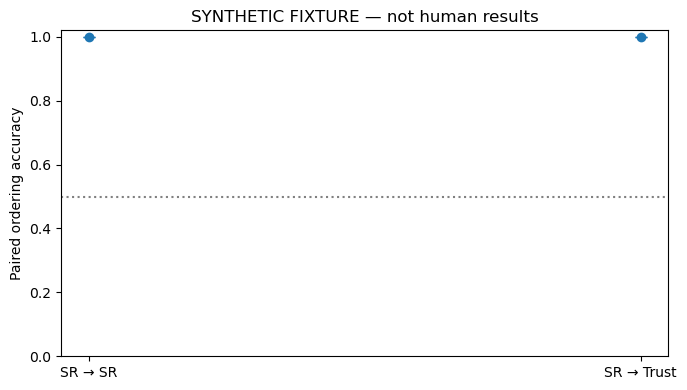

In [7]:
correct = (predictions > 0).astype(float)
rng = np.random.default_rng(SEED + 1)
bootstrap_ids = rng.integers(0, len(subjects), size=(2000, len(subjects)))
boot = correct[bootstrap_ids].mean(axis=1)
limits = np.quantile(boot, [0.025, 0.975], axis=0)
performance = pd.DataFrame({"evaluation": ["SR → SR", "SR → Trust"], "n": len(subjects),
    "paired_ordering_accuracy": correct.mean(axis=0), "ci_low": limits[0], "ci_high": limits[1],
    "data_mode": MODE})
display(performance)
fig, ax = plt.subplots(figsize=(7, 4))
values = performance.paired_ordering_accuracy.to_numpy()
ax.errorbar(np.arange(2), values, yerr=np.stack([values - limits[0], limits[1] - values]), fmt="o", capsize=4)
ax.axhline(0.5, color="gray", ls=":")
ax.set(xticks=np.arange(2), xticklabels=performance.evaluation, ylim=(0, 1.02),
       ylabel="Paired ordering accuracy", title=LABEL)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "performance.png", dpi=150)
plt.show()

## 7. Coefficients and forward patterns

A coefficient weights a feature in the classifier's decision rule. Correlated voxels can have weights that are difficult to interpret individually. A Haufe-style forward pattern describes covariance between features and the learned score; it is still model-dependent and is not a causal or region-specific importance test.

For a compact display, average the five training-fold coefficient maps and the five corresponding training-fold forward patterns. These training sets overlap, so similarity across folds is not independent replication. The figures use separate scales and show the central axial slice for illustration; they are not thresholded inference maps.

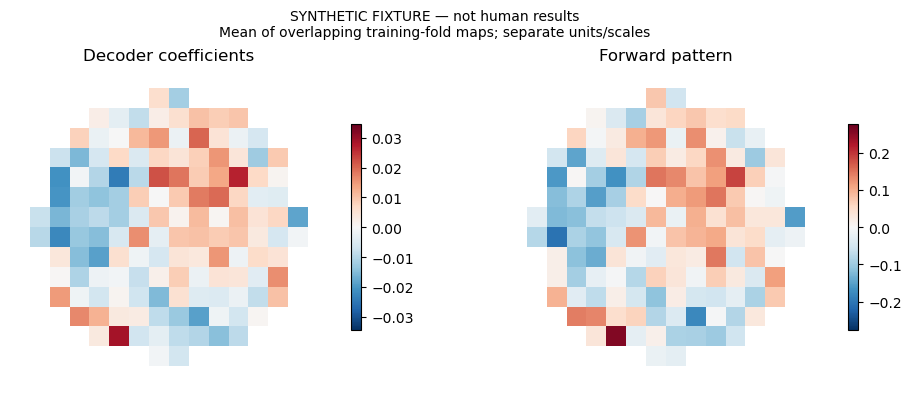

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title in zip(axes, [np.mean(weights, axis=0), np.mean(forward_patterns, axis=0)],
                           ["Decoder coefficients", "Forward pattern"]):
    volume = np.zeros(reference.shape, dtype="float32")
    volume[mask] = values
    display_image = nib.as_closest_canonical(nib.Nifti1Image(volume, reference.affine))
    data = display_image.get_fdata()
    plane = data[:, :, data.shape[2] // 2].T
    limit = float(np.max(np.abs(data)))
    assert limit > 0
    view = ax.imshow(np.ma.masked_equal(plane, 0), origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(title)
    ax.set_axis_off()
    fig.colorbar(view, ax=ax, shrink=0.65)
fig.suptitle(LABEL + "\nMean of overlapping training-fold maps; separate units/scales", fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "patterns.png", dpi=150)
plt.show()

## 8. What can we conclude?

- In synthetic mode, this verifies the workflow only; simulated accuracy says nothing about human social processing.
- In public mode, transfer would demonstrate prediction across these particular task contrasts in held-out tutorial participants. It would not by itself establish an abstract or uniquely social representation.
- Partner faces, relational context, task-related deactivation and other shared features can contribute to decoding. The tutorial does not resolve all such explanations.
- Tutorial analyses must not be fed back into selection of the paper's frozen signature or claims about independent validation.

**Exercises:** explain why random map-wise splits leak participant information; identify what changes when averaging outcome valence; compare the interpretations of coefficients and forward patterns; propose a future independent validation test without accessing reserved samples.

## 9. Record the environment and runtime

The template recommends `watermark` and records the Neurodesktop image version. The offline draft also prints package versions if `watermark` is unavailable. Install the documented dependencies and confirm watermark execution before submitting to NeurodeskEDU.

Runtime below is a measurement of this execution. Synthetic runtime and peak memory are not forecasts of the real-data notebook; Jacob and Riccardo should measure a fresh public-data run in Neurodesk Play.

In [9]:
if importlib.util.find_spec("watermark") is not None:
    get_ipython().run_line_magic("load_ext", "watermark")
    get_ipython().run_line_magic("watermark", "--iversions")
else:
    print("Draft environment: watermark unavailable; install the requirements before submission.")
versions = {package: importlib.metadata.version(package) for package in
            ("numpy", "pandas", "scikit-learn", "nibabel", "matplotlib")}
record = {"mode": MODE, "python": platform.python_version(), "packages": versions,
    "neurodesktop_image": os.environ.get("JUPYTER_IMAGE", os.environ.get("NEURODESKTOP_VERSION", "not running in Neurodesk")),
    "n": len(subjects), "input_map_files": len(manifest), "masked_voxels": int(mask.sum()),
    "recorded_compressed_map_bytes": int(manifest.byte_size.sum()), "feature_array_bytes": int(X.nbytes),
    "elapsed_seconds": time.perf_counter() - STARTED, "real_public_data_used": MODE == "public"}
print(json.dumps(record, indent=2))
(OUTPUT_DIR / "execution_summary.json").write_text(json.dumps(record, indent=2) + "\n")
performance.to_csv(OUTPUT_DIR / "performance.csv", index=False)
print("Completed:", LABEL)

Draft environment: watermark unavailable; install the requirements before submission.
{
  "mode": "synthetic",
  "python": "3.13.5",
  "packages": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "nibabel": "5.3.2",
    "matplotlib": "3.10.0"
  },
  "neurodesktop_image": "not running in Neurodesk",
  "n": 32,
  "input_map_files": 384,
  "masked_voxels": 968,
  "recorded_compressed_map_bytes": 1601364,
  "feature_array_bytes": 495616,
  "elapsed_seconds": 3.1139570829982404,
  "real_public_data_used": false
}
Completed: SYNTHETIC FIXTURE — not human results
